# 🏥 Hospital Multi-Model AI Diagnostic & Cost Prediction System

🎯 Problem Statement

Hospitals and insurance providers face delays and inefficiencies due to manual, disconnected workflows for:

Estimating patient medical insurance costs.

💡 Proposed Solution

A unified AI-powered platform integrating a core capability:

Medical Cost Estimation: Machine Learning regression models to predict insurance expenses.

## Import Libiraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import GridSearchCV

## Load Data

In [ ]:
data = pd.read_csv('medical_insurance.csv')
df= data.copy()
pd.set_option('display.max_columns', None)
df.head()


,person_id,age,sex,region,urban_rural,income,education,marital_status,employment_status,household_size,dependents,bmi,smoker,alcohol_freq,visits_last_year,hospitalizations_last_3yrs,days_hospitalized_last_3yrs,medication_count,systolic_bp,diastolic_bp,ldl,hba1c,plan_type,network_tier,deductible,copay,policy_term_years,policy_changes_last_2yrs,provider_quality,risk_score,annual_medical_cost,annual_premium,monthly_premium,claims_count,avg_claim_amount,total_claims_paid,chronic_count,hypertension,diabetes,asthma,copd,cardiovascular_disease,cancer_history,kidney_disease,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
0,75722,52,Female,North,Suburban,22700.0,Doctorate,Married,Retired,3,1,27.4,Never,NaN,2,0,0,4,121.0,76.0,123.8,5.28,PPO,Bronze,1000,20,4,0,3.73,0.5714,6938.06,876.05,73.00,1,4672.59,4672.59,1,0,0,0,0,0,0,0,0,1,0,1,0,2,0,1,0,0
1,80185,79,Female,North,Urban,12800.0,No HS,Married,Employed,3,1,26.6,Never,Weekly,2,0,0,3,131.0,79.0,97.3,4.82,POS,Gold,1000,10,1,0,3.10,1.0000,1632.61,445.10,37.09,4,297.27,1189.08,2,0,0,0,0,0,0,0,0,1,1,0,0,1,0,1,1,0
2,19865,68,Male,North,Rural,40700.0,HS,Married,Retired,5,3,31.5,Never,NaN,1,0,0,4,160.0,84.0,129.5,5.51,HMO,Platinum,500,20,10,0,3.90,1.0000,7661.01,1538.02,128.17,0,0.00,0.00,3,1,0,0,0,0,1,0,0,0,1,1,0,2,1,0,1,0
3,76700,15,Male,North,Suburban,15600.0,Some College,Married,Self-employed,5,3,31.6,Never,NaN,0,0,0,1,104.0,68.0,160.3,8.50,HMO,Silver,500,20,5,0,3.89,0.2857,5130.27,820.63,68.39,0,0.00,0.00,1,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
4,92992,53,Male,Central,Suburban,89600.0,Doctorate,Married,Self-employed,2,0,30.5,Never,Daily,3,0,0,2,136.0,83.0,171.0,5.20,POS,Platinum,500,10,7,0,3.90,0.8681,1700.73,500.93,41.74,1,1002.24,1002.24,2,1,0,0,0,0,0,0,0,1,0,2,0,1,1,0,1,0


## Data Overview

In [ ]:
df.shape

(100000, 54)

In [ ]:
df.columns

Index(['person_id', 'age', 'sex', 'region', 'urban_rural', 'income',
       'education', 'marital_status', 'employment_status', 'household_size',
       'dependents', 'bmi', 'smoker', 'alcohol_freq', 'visits_last_year',
       'hospitalizations_last_3yrs', 'days_hospitalized_last_3yrs',
       'medication_count', 'systolic_bp', 'diastolic_bp', 'ldl', 'hba1c',
       'plan_type', 'network_tier', 'deductible', 'copay', 'policy_term_years',
       'policy_changes_last_2yrs', 'provider_quality', 'risk_score',
       'annual_medical_cost', 'annual_premium', 'monthly_premium',
       'claims_count', 'avg_claim_amount', 'total_claims_paid',
       'chronic_count', 'hypertension', 'diabetes', 'asthma', 'copd',
       'cardiovascular_disease', 'cancer_history', 'kidney_disease',
       'liver_disease', 'arthritis', 'mental_health', 'proc_imaging_count',
       'proc_surgery_count', 'proc_physio_count', 'proc_consult_count',
       'proc_lab_count', 'is_high_risk', 'had_major_procedure'],
      

In [ ]:
data_info = df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 54 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   person_id                    100000 non-null  int64  
 1   age                          100000 non-null  int64  
 2   sex                          100000 non-null  object 
 3   region                       100000 non-null  object 
 4   urban_rural                  100000 non-null  object 
 5   income                       100000 non-null  float64
 6   education                    100000 non-null  object 
 7   marital_status               100000 non-null  object 
 8   employment_status            100000 non-null  object 
 9   household_size               100000 non-null  int64  
 10  dependents                   100000 non-null  int64  
 11  bmi                          100000 non-null  float64
 12  smoker                       100000 non-null  object 
 13  

In [ ]:
print('Descriptive Statistics(Numerical) :')
df.describe()

Descriptive Statistics(Numerical) :


,person_id,age,income,household_size,dependents,bmi,visits_last_year,hospitalizations_last_3yrs,days_hospitalized_last_3yrs,medication_count,systolic_bp,diastolic_bp,ldl,hba1c,deductible,copay,policy_term_years,policy_changes_last_2yrs,provider_quality,risk_score,annual_medical_cost,annual_premium,monthly_premium,claims_count,avg_claim_amount,total_claims_paid,chronic_count,hypertension,diabetes,asthma,copd,cardiovascular_disease,cancer_history,kidney_disease,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
count,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000
mean,50000.500000,47.521500,4.987390e+04,2.430900,0.898380,26.990512,1.92765,0.093640,0.373350,1.236320,117.808970,73.604770,119.975065,5.605968,1226.725000,19.520400,5.517760,0.050690,3.598920,0.519849,3009.451907,582.320040,48.526668,1.62178,656.512084,1377.878827,0.724720,0.203450,0.085930,0.058870,0.035950,0.051170,0.021510,0.014620,0.014770,0.108310,0.130140,0.508530,0.158690,0.508390,0.50933,0.509140,0.367810,0.169700
std,28867.657797,15.988752,4.680021e+04,1.075126,0.950654,4.994883,1.73773,0.304848,1.373011,1.209358,15.369187,8.900924,30.262086,0.845996,1019.619375,10.286255,2.868827,0.224591,0.594052,0.250669,3127.462822,399.583722,33.298640,2.02982,1072.660048,2305.464687,0.805523,0.402566,0.280262,0.235382,0.186166,0.220345,0.145078,0.120027,0.120632,0.310773,0.336459,0.749755,0.463562,0.747218,0.75363,0.750455,0.482212,0.375371
min,1.000000,0.000000,1.100000e+03,1.000000,0.000000,12.000000,0.00000,0.000000,0.000000,0.000000,61.000000,40.000000,30.000000,3.540000,500.000000,10.000000,1.000000,0.000000,1.500000,0.000000,55.550000,211.670000,17.640000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
25%,25000.750000,37.000000,2.110000e+04,2.000000,0.000000,23.600000,1.00000,0.000000,0.000000,0.000000,107.000000,67.000000,99.400000,5.160000,500.000000,10.000000,3.000000,0.000000,3.200000,0.329700,1175.117500,352.070000,29.340000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
50%,50000.500000,48.000000,3.620000e+04,2.000000,1.000000,27.000000,2.00000,0.000000,0.000000,1.000000,117.000000,73.000000,120.000000,5.440000,1000.000000,20.000000,6.000000,0.000000,3.600000,0.505500,2082.575000,463.585000,38.630000,1.00000,318.015000,642.545000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
75%,75000.250000,58.000000,6.220000e+04,3.000000,1.000000,30.400000,3.00000,0.000000,0.000000,2.000000,128.000000,79.000000,140.300000,5.760000,2000.000000,30.000000,8.000000,0.000000,4.010000,0.703300,3707.957500,666.697500,55.560000,2.00000,872.215000,1795.522500,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.00000,1.000000,1.000000,0.000000
max,100000.000000,100.000000,1.061800e+06,9.000000,7.000000,50.400000,25.00000,3.000000,21.000000,11.000000,183.000000,114.000000,248.300000,11.940000,5000.000000,50.000000,10.000000,2.000000,5.000000,1.000000,65724.9000

In [ ]:
print('Descriptive Statistics(Categorical) :')
df.describe(include='object')

Descriptive Statistics(Categorical) :


,sex,region,urban_rural,education,marital_status,employment_status,smoker,alcohol_freq,plan_type,network_tier
count,100000,100000,100000,100000,100000,100000,100000,69917,100000,100000
unique,3,5,3,6,4,4,3,3,4,4
top,Female,South,Urban,Bachelors,Married,Employed,Never,Occasional,PPO,Silver
freq,49193,28029,60019,27996,53252,55269,69709,45078,35167,40177


### Check Nulls

In [ ]:
df.isnull().sum()[df.isnull().sum() > 0]

,0
alcohol_freq,30083


### Duplicates

In [ ]:
df.duplicated().sum()

np.int64(0)

## EDA

In [ ]:
df['alcohol_freq'].value_counts(dropna=False)

,count
alcohol_freq,
Occasional,45078
NaN,30083
Weekly,19833
Daily,5006


In [ ]:
df['alcohol_freq'].value_counts(normalize=True, dropna=False)

,proportion
alcohol_freq,
Occasional,0.45078
NaN,0.30083
Weekly,0.19833
Daily,0.05006


### Target Distribution

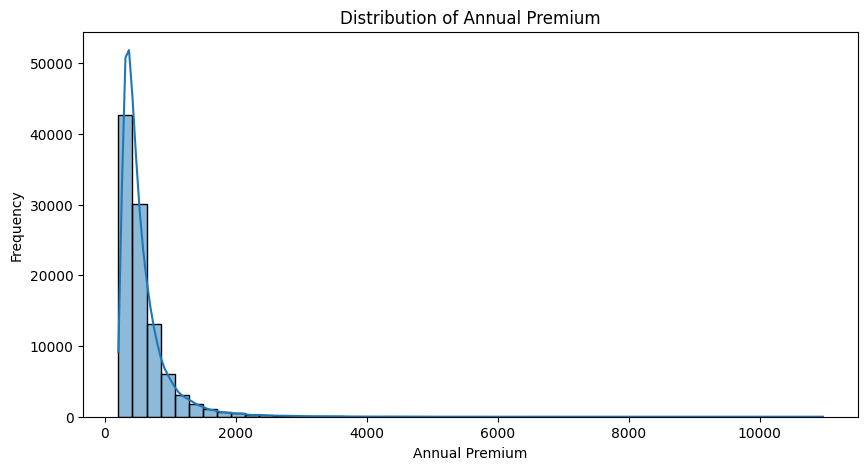

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(df['annual_premium'], bins=50, kde=True)

plt.title('Distribution of Annual Premium')
plt.xlabel('Annual Premium')
plt.ylabel('Frequency')

plt.show()

### Outlires

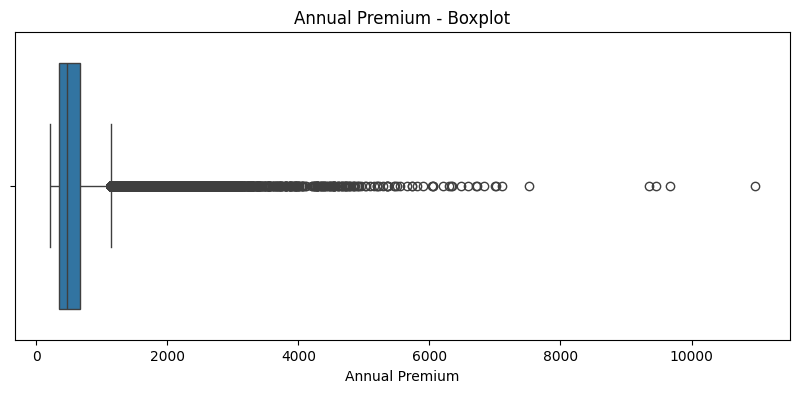

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['annual_premium'])

plt.title('Annual Premium - Boxplot')
plt.xlabel('Annual Premium')

plt.show()

### Smoker vs annual_premium

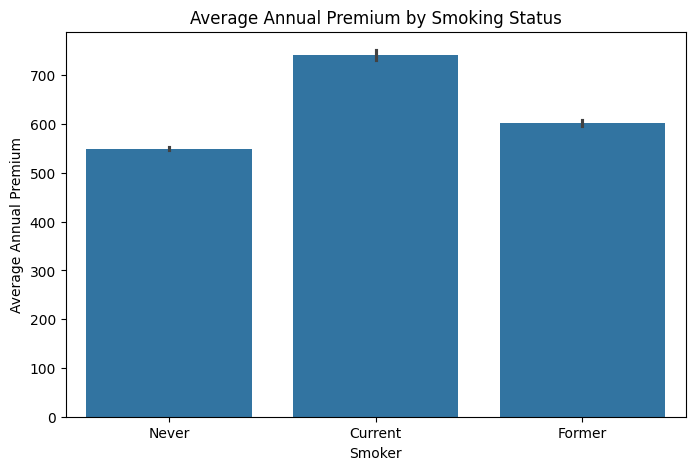

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x='smoker', y='annual_premium', estimator='mean')

plt.title('Average Annual Premium by Smoking Status')
plt.xlabel('Smoker')
plt.ylabel('Average Annual Premium')

plt.show()

### Age vs Annual Premium

In [ ]:
age_premium = df.groupby('age')['annual_premium'].mean().reset_index()

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=age_premium,
    x='age',
    y='annual_premium',
    marker='o'
)

plt.title('Average Annual Premium by Age')
plt.xlabel('Age')
plt.ylabel('Average Annual Premium')

plt.show()

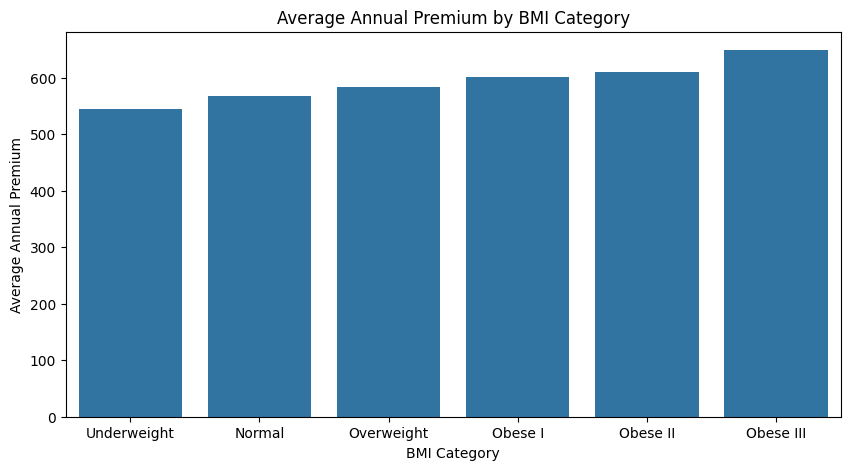

In [ ]:
bmi_bins = [0, 18.5, 25, 30, 35, 40, float('inf')]
bmi_labels = ['Underweight', 'Normal', 'Overweight', 'Obese I', 'Obese II', 'Obese III']

df['bmi_category'] = pd.cut(
    df['bmi'],
    bins=bmi_bins,
    labels=bmi_labels
)

bmi_premium = df.groupby(
    'bmi_category',
    observed=True
)['annual_premium'].mean().reset_index()

plt.figure(figsize=(10, 5))

sns.barplot(
    data=bmi_premium,
    x='bmi_category',
    y='annual_premium'
)

plt.title('Average Annual Premium by BMI Category')
plt.xlabel('BMI Category')
plt.ylabel('Average Annual Premium')

plt.show()

### relationship between risk score and average annual premium.

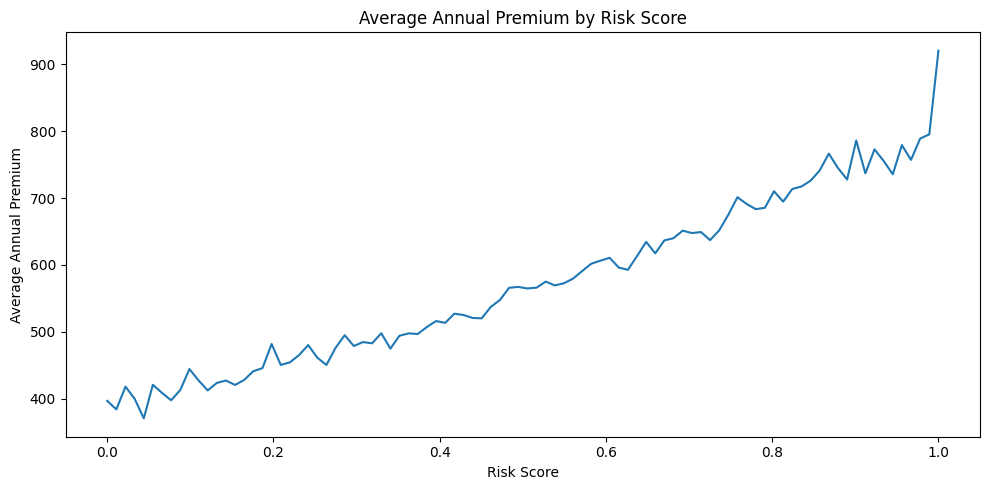

In [38]:
risk_premium = df.groupby('risk_score')['annual_premium'].mean().reset_index()
risk_premium = risk_premium.sort_values('risk_score')

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=risk_premium,
    x='risk_score',
    y='annual_premium'
)

plt.title('Average Annual Premium by Risk Score')
plt.xlabel('Risk Score')
plt.ylabel('Average Annual Premium')

plt.tight_layout()
plt.show()

### Annual Medical Cost Analysis

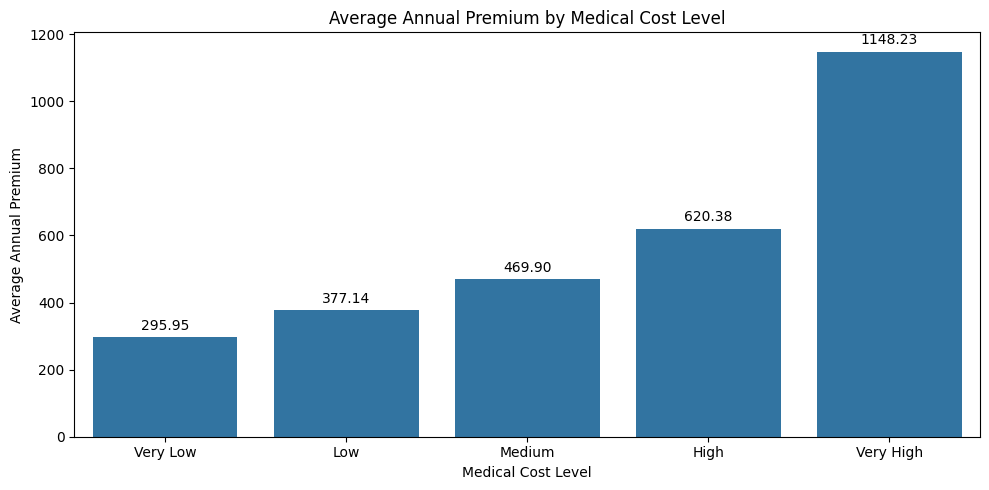

In [39]:
df['medical_cost_group'] = pd.qcut(
    df['annual_medical_cost'],
    q=5,
    labels=['Very Low', 'Low', 'Medium', 'High', 'Very High']
)

cost_premium = df.groupby(
    'medical_cost_group',
    observed=True
)['annual_premium'].mean().reset_index()

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=cost_premium,
    x='medical_cost_group',
    y='annual_premium'
)

plt.title('Average Annual Premium by Medical Cost Level')
plt.xlabel('Medical Cost Level')
plt.ylabel('Average Annual Premium')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

###  Plan Type Analysis


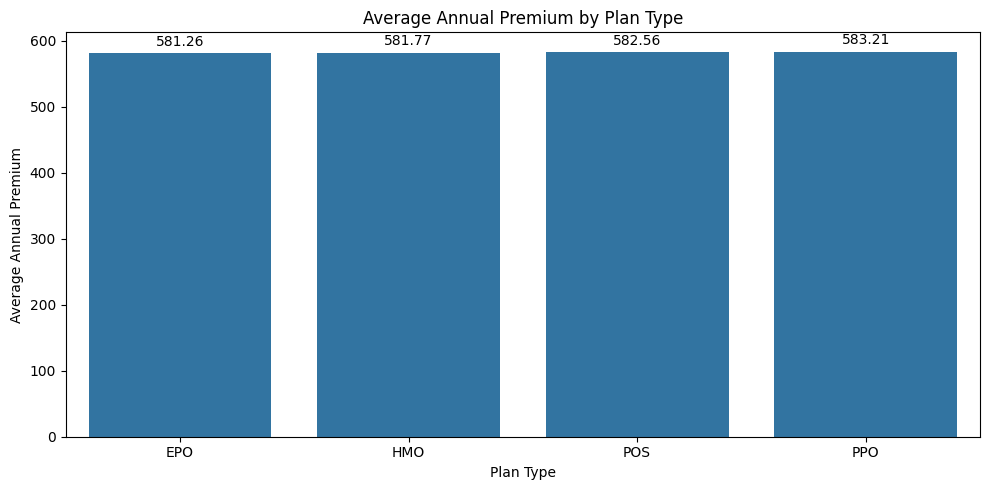

In [40]:
plan_premium = df.groupby('plan_type')['annual_premium'].mean().reset_index()

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=plan_premium,
    x='plan_type',
    y='annual_premium'
)

plt.title('Average Annual Premium by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Average Annual Premium')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

###  Network Tier Analysis


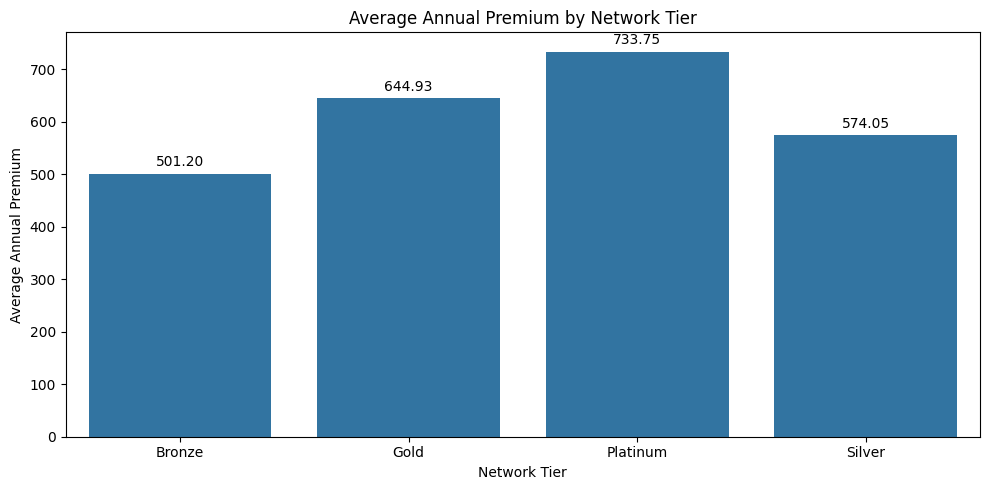

In [41]:
network_premium = df.groupby('network_tier')['annual_premium'].mean().reset_index()

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=network_premium,
    x='network_tier',
    y='annual_premium'
)

plt.title('Average Annual Premium by Network Tier')
plt.xlabel('Network Tier')
plt.ylabel('Average Annual Premium')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

### Claims Count

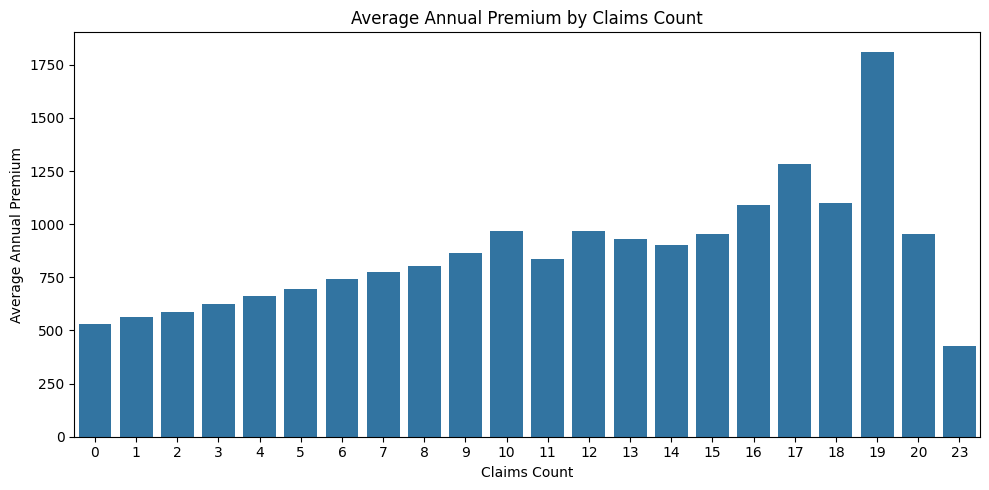

In [43]:
claims_premium = df.groupby('claims_count')['annual_premium'].mean().reset_index()

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=claims_premium,
    x='claims_count',
    y='annual_premium'
)

plt.title('Average Annual Premium by Claims Count')
plt.xlabel('Claims Count')
plt.ylabel('Average Annual Premium')


plt.tight_layout()
plt.show()

### Chronic Disease Count

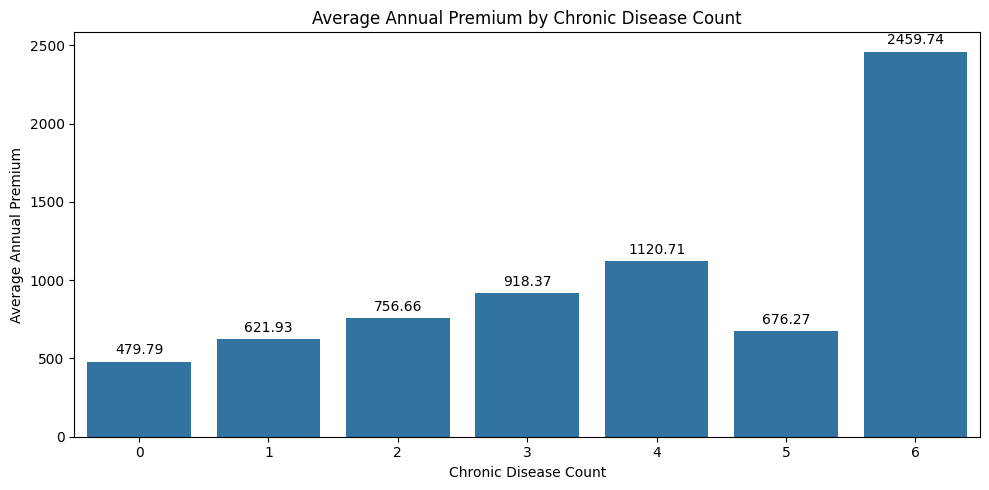

In [44]:
chronic_premium = df.groupby('chronic_count')['annual_premium'].mean().reset_index()

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=chronic_premium,
    x='chronic_count',
    y='annual_premium'
)

plt.title('Average Annual Premium by Chronic Disease Count')
plt.xlabel('Chronic Disease Count')
plt.ylabel('Average Annual Premium')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

### High Risk Status

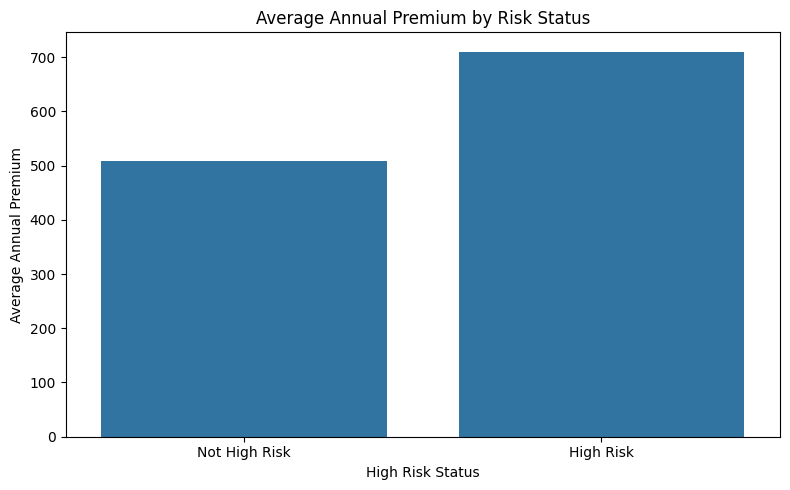

In [46]:
risk_premium = df.groupby('is_high_risk')['annual_premium'].mean().reset_index()

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=risk_premium,
    x='is_high_risk',
    y='annual_premium'
)

plt.title('Average Annual Premium by Risk Status')
plt.xlabel('High Risk Status')
plt.ylabel('Average Annual Premium')



plt.xticks([0, 1], ['Not High Risk', 'High Risk'])

plt.tight_layout()
plt.show()

###Corr

In [50]:
corr = df.corr(numeric_only=True)['annual_premium'].sort_values(ascending=False)
print(corr)



annual_premium                 1.000000
annual_medical_cost            0.965415
total_claims_paid              0.713764
avg_claim_amount               0.608786
risk_score                     0.295859
chronic_count                  0.286698
is_high_risk                   0.244012
days_hospitalized_last_3yrs    0.222634
hospitalizations_last_3yrs     0.201935
visits_last_year               0.188857
claims_count                   0.173622
hypertension                   0.147329
had_major_procedure            0.142128
systolic_bp                    0.139419
age                            0.127473
mental_health                  0.121460
diastolic_bp                   0.114142
arthritis                      0.111821
medication_count               0.108598
diabetes                       0.104391
hba1c                          0.081799
asthma                         0.079231
cardiovascular_disease         0.076415
proc_surgery_count             0.074306
copd                           0.066949


## Data Cleaning , Preprocessing

### Drop Columns

In [52]:
df = df.drop(columns=['person_id', 'monthly_premium'], errors='ignore')

### Handel nulls

In [48]:
df['alcohol_freq'] = df['alcohol_freq'].fillna('Unknown')

print(df['alcohol_freq'].isnull().sum())

0


## Machine Learning

###Feature Selection

In [55]:
features = [
    'age',
    'bmi',
    'smoker',
    'annual_medical_cost',
    'risk_score',
    'chronic_count',
    'is_high_risk',
    'hospitalizations_last_3yrs',
    'visits_last_year',
    'claims_count'
]

x = df[features]

y = df['annual_premium']

### Train Test Split

In [58]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

###numeric and categorical

In [59]:
 numerical_features = [
    'age',
    'bmi',
    'annual_medical_cost',
    'risk_score',
    'chronic_count',
    'is_high_risk',
    'hospitalizations_last_3yrs',
    'visits_last_year',
    'claims_count'
]

categorical_features = [
    'smoker'
]

### Column Transformer

In [60]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)



### Linera Regression

In [61]:
linear_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

In [62]:
linear_pipeline.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi',
                                                   'annual_medical_cost',
                                                   'risk_score',
                                                   'chronic_count',
                                                   'is_high_risk',
                                                   'hospitalizations_last_3yrs',
                                                   'visits_last_year',
                                                   'claims_count']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['smoker'])])),
                ('model', LinearRegression())])

### Prediction

In [63]:
y_pred = linear_pipeline.predict(x_test)

### Evaluation

In [64]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Linear Regression")
print("RMSE:", rmse)
print("MAE:", mae)
print("R²:", r2)

Linear Regression
RMSE: 103.67326599464387
MAE: 57.87212476817018
R²: 0.9324624144450279


In [65]:
results = []

results.append({
    'Model': 'Linear Regression',
    'RMSE': rmse,
    'MAE': mae,
    'R²': r2
})

results

[{'Model': 'Linear Regression',
  'RMSE': np.float64(103.67326599464387),
  'MAE': 57.87212476817018,
  'R²': 0.9324624144450279}]

### RandomForset

In [66]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

### GridSearch

In [77]:
param_grid = {
    'model__n_estimators': [50, 100],
    'model__max_depth': [10, 20],
    'model__min_samples_split': [2, 5]
}

In [78]:
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

In [79]:
grid_search.fit(x_train, y_train)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['age',
                                                                          'bmi',
                                                                          'annual_medical_cost',
                                                                          'risk_score',
                                                                          'chronic_count',
                                                                          'is_high_risk',
                                                                          'hospitalizations_last_3yrs',
                                                                          'visits_last_year',
                                                                          'claims_count']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['smoker'])])),
                                       ('model',
                                        RandomForestRegressor(n_jobs=-1,
                                                              random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [10, 20],
                         'model__min_samples_split': [2, 5],
                         'model__n_estimators': [50, 100]},
             scoring='neg_root_mean_squared_error', verbose=1)

In [80]:
print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV RMSE:")
print(-grid_search.best_score_)

Best Parameters:
{'model__max_depth': 10, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best CV RMSE:
107.34853929342897


### Predection

In [81]:
best_rf = grid_search.best_estimator_

y_pred_rf = best_rf.predict(x_test)

### Evaluation

In [82]:
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Tuned Random Forest")
print("RMSE:", rmse_rf)
print("MAE:", mae_rf)
print("R²:", r2_rf)

Tuned Random Forest
RMSE: 105.21700475760476
MAE: 58.193657394855364
R²: 0.9304361132881194


In [83]:
results.append({
    'Model': 'Tuned Random Forest',
    'RMSE': rmse_rf,
    'MAE': mae_rf,
    'R²': r2_rf
})

results

[{'Model': 'Linear Regression',
  'RMSE': np.float64(103.67326599464387),
  'MAE': 57.87212476817018,
  'R²': 0.9324624144450279},
 {'Model': 'Tuned Random Forest',
  'RMSE': np.float64(105.21700475760476),
  'MAE': 58.193657394855364,
  'R²': 0.9304361132881194}]

##XGBoost

### Pipeline

In [84]:
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

In [93]:
param_grid_xgb = {
    'model__n_estimators': [50, 100,200],
    'model__max_depth': [3, 6],
    'model__learning_rate': [0.05, 0.1]
}

In [95]:
grid_search_xgb = GridSearchCV(
    xgb_pipeline,
    param_grid=param_grid_xgb,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1)

In [96]:
grid_search_xgb.fit(x_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['age',
                                                                          'bmi',
                                                                          'annual_medical_cost',
                                                                          'risk_score',
                                                                          'chronic_count',
                                                                          'is_high_risk',
                                                                          'hospitalizations_last_3yrs',
                                                                          'visits_last_year',
                                                                          'claims_count']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['smoker'])])),
                                       ('model',
                                        XGBRegressor(base_sc...
                                                     max_delta_step=None,
                                                     max_depth=None,
                                                     max_leaves=None,
                                                     min_child_weight=None,
                                                     missing=nan,
                                                     monotone_constraints=None,
                                                     multi_strategy=None,
                                                     n_estimators=None,
                                                     n_jobs=-1,
                                                     num_parallel_tree=None, ...))]),
             n_jobs=-1,
             param_grid={'model__learning_rate': [0.05, 0.1],
                         'model__max_depth': [3, 6],
                         'model__n_estimators': [50, 100, 200]},
             scoring='neg_root_mean_squared_error', verbose=1)

In [97]:
print("Best Parameters:")
print(grid_search_xgb.best_params_)

print("Best CV RMSE:")
print(-grid_search_xgb.best_score_)

Best Parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100}
Best CV RMSE:
120.47292683628845


### Prediction

In [100]:
best_xgb = grid_search_xgb.best_estimator_
y_pred_xgb = best_xgb.predict(x_test)


###Evaluation

In [101]:
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print("Tuned XGBoost")
print("RMSE:", rmse_xgb)
print("MAE:", mae_xgb)
print("R²:", r2_xgb)

Tuned XGBoost
RMSE: 128.3817463073587
MAE: 59.61147635769653
R²: 0.8964336840208412


In [102]:
results.append({
    'Model': 'Tuned XGBoost',
    'RMSE': rmse_xgb,
    'MAE': mae_xgb,
    'R²': r2_xgb
})

results

[{'Model': 'Linear Regression',
  'RMSE': np.float64(103.67326599464387),
  'MAE': 57.87212476817018,
  'R²': 0.9324624144450279},
 {'Model': 'Tuned Random Forest',
  'RMSE': np.float64(105.21700475760476),
  'MAE': 58.193657394855364,
  'R²': 0.9304361132881194},
 {'Model': 'Tuned XGBoost',
  'RMSE': np.float64(128.3817463073587),
  'MAE': 59.61147635769653,
  'R²': 0.8964336840208412}]

### Feature Importance/coefficients

In [103]:
feature_names = best_rf.named_steps['preprocessor'].get_feature_names_out()

In [104]:
feature_names = linear_pipeline.named_steps['preprocessor'].get_feature_names_out()

coefficients = linear_pipeline.named_steps['model'].coef_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

feature_importance['Absolute_Coefficient'] = (
    feature_importance['Coefficient'].abs()
)

feature_importance = feature_importance.sort_values(
    'Absolute_Coefficient',
    ascending=False
)

feature_importance.head(10)

,Feature,Coefficient,Absolute_Coefficient
2,num__annual_medical_cost,385.661061,385.661061
3,num__risk_score,-6.542370,6.542370
0,num__age,4.259318,4.259318
4,num__chronic_count,3.737389,3.737389
9,cat__smoker_Current,3.668052,3.668052
10,cat__smoker_Former,-1.937608,1.937608
11,cat__smoker_Never,-1.730444,1.730444
5,num__is_high_risk,0.669972,0.669972
1,num__bmi,0.459121,0.459121
8,num__claims_count,0.348136,0.348136


#### Top 5 most important features: annual_medical_cost, risk_score, age, chronic_count, and smoker.

### linerar model on top 5 features

In [105]:
features = [
    'annual_medical_cost',
    'risk_score',
    'age',
    'chronic_count',
    'smoker'
]

X = df[features]

y = df['annual_premium']

In [106]:
X_train_5, X_test_5, y_train_5, y_test_5 = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [107]:
numerical_features_5 = [
    'annual_medical_cost',
    'risk_score',
    'age',
    'chronic_count'
]

categorical_features_5 = [
    'smoker'
]

preprocessor_5 = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features_5),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features_5)
    ]
)

In [108]:
linear_pipeline_5 = Pipeline([
    ('preprocessor', preprocessor_5),
    ('model', LinearRegression())
])

linear_pipeline_5.fit(X_train_5, y_train_5)

y_pred_5 = linear_pipeline_5.predict(X_test_5)

In [109]:
rmse_5 = np.sqrt(mean_squared_error(y_test_5, y_pred_5))
mae_5 = mean_absolute_error(y_test_5, y_pred_5)
r2_5 = r2_score(y_test_5, y_pred_5)

print("Linear Regression - Top 5 Features")
print("RMSE:", rmse_5)
print("MAE:", mae_5)
print("R²:", r2_5)

Linear Regression - Top 5 Features
RMSE: 103.67608858071382
MAE: 57.87649016611769
R²: 0.9324587368673729


### Save

In [115]:
import joblib

joblib.dump(
    linear_pipeline_5,
    'insurance_cost_model.pkl'
)

['insurance_cost_model.pkl']